# Lab 1.3: From Templates to Features — What One Hidden Layer Does to the Weights

**MNIST internals series.** [Lab 1.1](/posts/ml/labs/2026-10-19-lab-1-mnist-from-pixels-to-neural-network/) gave us the clean answer: in a linear softmax model, a weight row is a matched-filter photograph of its class. [Lab 1.2](/posts/ml/labs/2026-10-19-lab-2-continual-learning-1-2-then-3/) showed those photographs being painted, re-carved, and out-bid.

Now the question this series was really building toward: **add one hidden layer. What happens to the weight picture?**

If you've watched 3Blue1Brown's neural nets series, you might expect: "layers learn edges, then curves, then parts; visualizing raw weights won't tell you much here." We can now test that ourselves instead of taking it on faith, and the truth lands in a more interesting place:

1. **First-layer weights stay visualizable** — they still live in pixel space. But what they show changes completely: not classes, but *parts*. You will see the "edgelets and stroke fragments" with your own eyes by the end of §3.
2. **The second layer is where visualization truly dies** — 128 hidden activations don't reshape into any image. There, class knowledge dissolves into *routing coefficients over parts*, and we need new instruments: dataset search ("what makes this neuron fire?") and **activation maximization** — the Distill tool, built from scratch.
3. Along the way: lesion studies (causal, not just correlational), "dreams" of each digit class, and a measurement of why the 92% confusions from Lab 1.1 get fixed.

Everything is still float64 NumPy, backprop written by hand and verified numerically before we trust a single picture.

## 0. Setup

Architecture: $784 \to 128 \;(\mathrm{ReLU}) \to 10 \;(\mathrm{softmax})$. Same data, same training ritual, checkpoints every epoch as before.

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

from mnist_lab import (load_mnist, one_hot, show_grid, show_confusion,
                       save_fig, save_ckpt, load_ckpt, manifest)

rng = np.random.default_rng(3)
x_train, y_train, x_test, y_test = load_mnist("data")
CKPT = Path("checkpoints/lab03"); FIGS = Path("figures/lab03"); FIGS.mkdir(parents=True, exist_ok=True)
print("python:", sys.version.split()[0], "| numpy:", np.__version__, "| data:", x_train.shape, x_test.shape)

python: 3.14.3 | numpy: 2.5.4 | data: (60000, 784) (10000, 784)


## 1. The model, and its gradients on paper first

**Forward:**
$$z_1 = xW_1^\top + b_1 \qquad a_1 = \max(z_1, 0) \qquad z_2 = a_1W_2^\top + b_2 \qquad \hat p = \mathrm{softmax}(z_2)$$

**Backward** (chain rule, exactly the dense-network derivation from the [backprop notes](/posts/ml/2026-09-12-3-backpropagation-in-a-fully-connected-network) — written out because every claim in this lab depends on it):

$$\delta_2 = \tfrac1N (\hat p - y) \qquad \frac{\partial \mathcal{L}}{\partial W_2} = \delta_2^\top a_1 \qquad \delta_1 = (\delta_2 W_2) \odot \mathbb{1}[z_1 > 0] \qquad \frac{\partial \mathcal{L}}{\partial W_1} = \delta_1^\top x$$

The piece that is new relative to Lab 1.1 is $\delta_1$: the information flowing into a first-layer weight is gated by the ReLU mask $\mathbb{1}[z_1>0]$ **and** routed through $W_2$. A first-layer row no longer learns "what class $c$ looks like" — it learns *"something the assembler layer finds useful to talk about."* Remember that sentence when we look at the pictures.

In [2]:
class MLP:
    """784 -> n_hidden (ReLU) -> 10 (softmax, cross-entropy). Plain SGD, float64."""
    def __init__(self, n_in, n_hidden, n_classes, rng):
        self.W1 = rng.normal(0, np.sqrt(2.0 / n_in), size=(n_hidden, n_in))   # He init for ReLU
        self.b1 = np.zeros(n_hidden)
        self.W2 = rng.normal(0, np.sqrt(2.0 / n_hidden), size=(n_classes, n_hidden))
        self.b2 = np.zeros(n_classes)

    def forward(self, x):
        z1 = x @ self.W1.T + self.b1
        a1 = np.maximum(z1, 0)
        z2 = a1 @ self.W2.T + self.b2
        return z1, a1, z2

    def probs(self, x):
        _, _, z2 = self.forward(x)
        z2 = z2 - z2.max(axis=1, keepdims=True)
        e = np.exp(z2)
        return e / e.sum(axis=1, keepdims=True)

    def loss(self, x, y):
        p = self.probs(x)
        return float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean())

    def grad(self, x, y):
        z1, a1, _ = self.forward(x)
        p = self.probs(x)
        d2 = (p - one_hot(y, self.W2.shape[0])) / len(y)
        gW2, gb2 = d2.T @ a1, d2.sum(axis=0)
        d1 = (d2 @ self.W2) * (z1 > 0)          # routed through W2, gated by ReLU mask
        gW1, gb1 = d1.T @ x, d1.sum(axis=0)
        return gW1, gb1, gW2, gb2

    def step(self, x, y, lr):
        gW1, gb1, gW2, gb2 = self.grad(x, y)
        self.W1 -= lr * gW1; self.b1 -= lr * gb1
        self.W2 -= lr * gW2; self.b2 -= lr * gb2

    def predict(self, x):    return self.forward(x)[2].argmax(axis=1)
    def accuracy(self, x, y): return float((self.predict(x) == y).mean())

print(f"parameters: {128*784 + 128 + 10*128 + 10:,}  (vs 7,860 for Lab 1.1's linear model)")

parameters: 101,770  (vs 7,860 for Lab 1.1's linear model)


In [3]:
xt, yt = x_train[:8].astype(np.float64), y_train[:8]
probe = MLP(784, 128, 10, np.random.default_rng(0))
gW1, gb1, gW2, gb2 = probe.grad(xt, yt)

eps, errs = 1e-6, []
def check(param, grad, idx):
    orig = param[idx]
    param[idx] = orig + eps; lp = probe.loss(xt, yt)
    param[idx] = orig - eps; lm = probe.loss(xt, yt)
    param[idx] = orig
    errs.append(abs(grad[idx] - (lp - lm) / (2 * eps)) / (1e-12 + abs(grad[idx]) + abs((lp - lm) / (2 * eps))))

r = np.random.default_rng(1)
for _ in range(12): check(probe.W1, gW1, tuple(r.integers(0, s) for s in probe.W1.shape))
for _ in range(12): check(probe.W2, gW2, tuple(r.integers(0, s) for s in probe.W2.shape))
for _ in range(4):  check(probe.b1, gb1, tuple([r.integers(0, 128)]))
for _ in range(4):  check(probe.b2, gb2, tuple([r.integers(0, 10)]))
print(f"max relative error over {len(errs)} probed parameters (all four tensors): {max(errs):.2e}")

max relative error over 32 probed parameters (all four tensors): 5.25e-08


## 2. Training

Same SGD ritual as before: batch 256, lr 0.1, 8 epochs, checkpoint at every epoch boundary. The comparison that matters: Lab 1.1's linear model plateaued at **92.09%**. Everything past that number, whatever it is, was bought by the hidden layer — and it is the hidden layer's internals we're here to open.

epoch 1: test acc = 0.9075  loss = 0.3277


epoch 2: test acc = 0.9217  loss = 0.2679


epoch 3: test acc = 0.9297  loss = 0.2328


epoch 4: test acc = 0.9339  loss = 0.2124


epoch 5: test acc = 0.9398  loss = 0.1924


...

epoch 20: test acc = 0.9698  loss = 0.0810


epoch 21: test acc = 0.9705  loss = 0.0802


epoch 22: test acc = 0.9707  loss = 0.0772


epoch 23: test acc = 0.9725  loss = 0.0752


epoch 24: test acc = 0.9723  loss = 0.0719

5616 steps in 7s | final: 0.9723  (linear model from Lab 1.1: 0.9209)
saved figure -> figures/lab03/training_curve.png


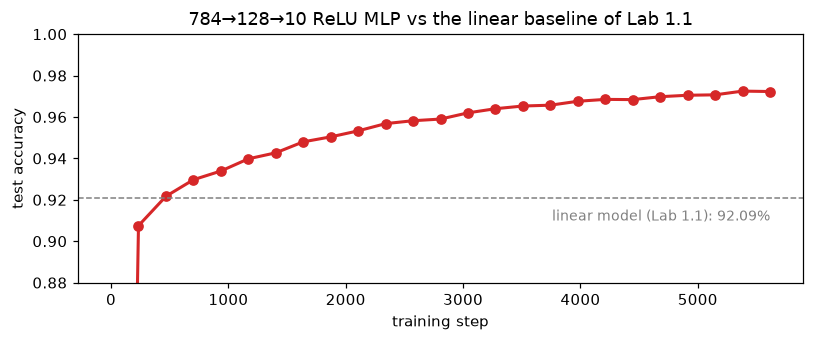

In [4]:
BATCH, LR, EPOCHS = 256, 0.1, 24
model = MLP(784, 128, 10, rng)
hist, snaps = [(0, model.accuracy(x_test, y_test), model.loss(x_train[::25], y_train[::25]))], {}
save_ckpt(CKPT, "epoch_0", step=0, metrics={"test_acc": round(model.accuracy(x_test, y_test), 4)},
          W1=model.W1, b1=model.b1, W2=model.W2, b2=model.b2)

t0, step = time.perf_counter(), 0
for epoch in range(1, EPOCHS + 1):
    perm = rng.permutation(len(x_train))
    perm = perm[: len(perm) // BATCH * BATCH]
    for i in perm.reshape(-1, BATCH):
        model.step(x_train[i], y_train[i], LR); step += 1
    acc, loss = model.accuracy(x_test, y_test), model.loss(x_train[::25], y_train[::25])
    hist.append((step, acc, loss)); snaps[epoch] = model.W1.copy()
    save_ckpt(CKPT, f"epoch_{epoch}", step=step, metrics={"test_acc": round(acc, 4), "loss": round(loss, 4)},
              W1=model.W1, b1=model.b1, W2=model.W2, b2=model.b2)
    print(f"epoch {epoch}: test acc = {acc:.4f}  loss = {loss:.4f}")

final_acc = model.accuracy(x_test, y_test)
print(f"\n{step} steps in {time.perf_counter() - t0:.0f}s | final: {final_acc:.4f}  (linear model from Lab 1.1: 0.9209)")

h = np.array(hist)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(h[:, 0], h[:, 1], "o-", color="tab:red", lw=2)
ax.axhline(0.9209, color="grey", ls="--", lw=1)
ax.text(step, 0.91, "linear model (Lab 1.1): 92.09%", ha="right", fontsize=9, color="grey")
ax.set_xlabel("training step"); ax.set_ylabel("test accuracy"); ax.set_ylim(0.88, 1.0)
ax.set_title("784→128→10 ReLU MLP vs the linear baseline of Lab 1.1")
fig.tight_layout(); save_fig(fig, FIGS / "training_curve.png"); plt.show()

## 3. The brute-force test: just plot all of $W_1$ anyway

A row of $W_1$ has 784 numbers, so the Lab 1.1 trick still *mechanically* works — reshape to 28×28, diverging colormap, blue votes for the neuron's pre-activation, red against. If 3b1b's caution ("plotting weights won't tell you much in a deep net") were fully right here, we'd see 128 panels of noise. If the "layers learn edges" story is right, we should see fragments. All 128, no cherry-picking:

saved figure -> figures/lab03/w1_gallery.png


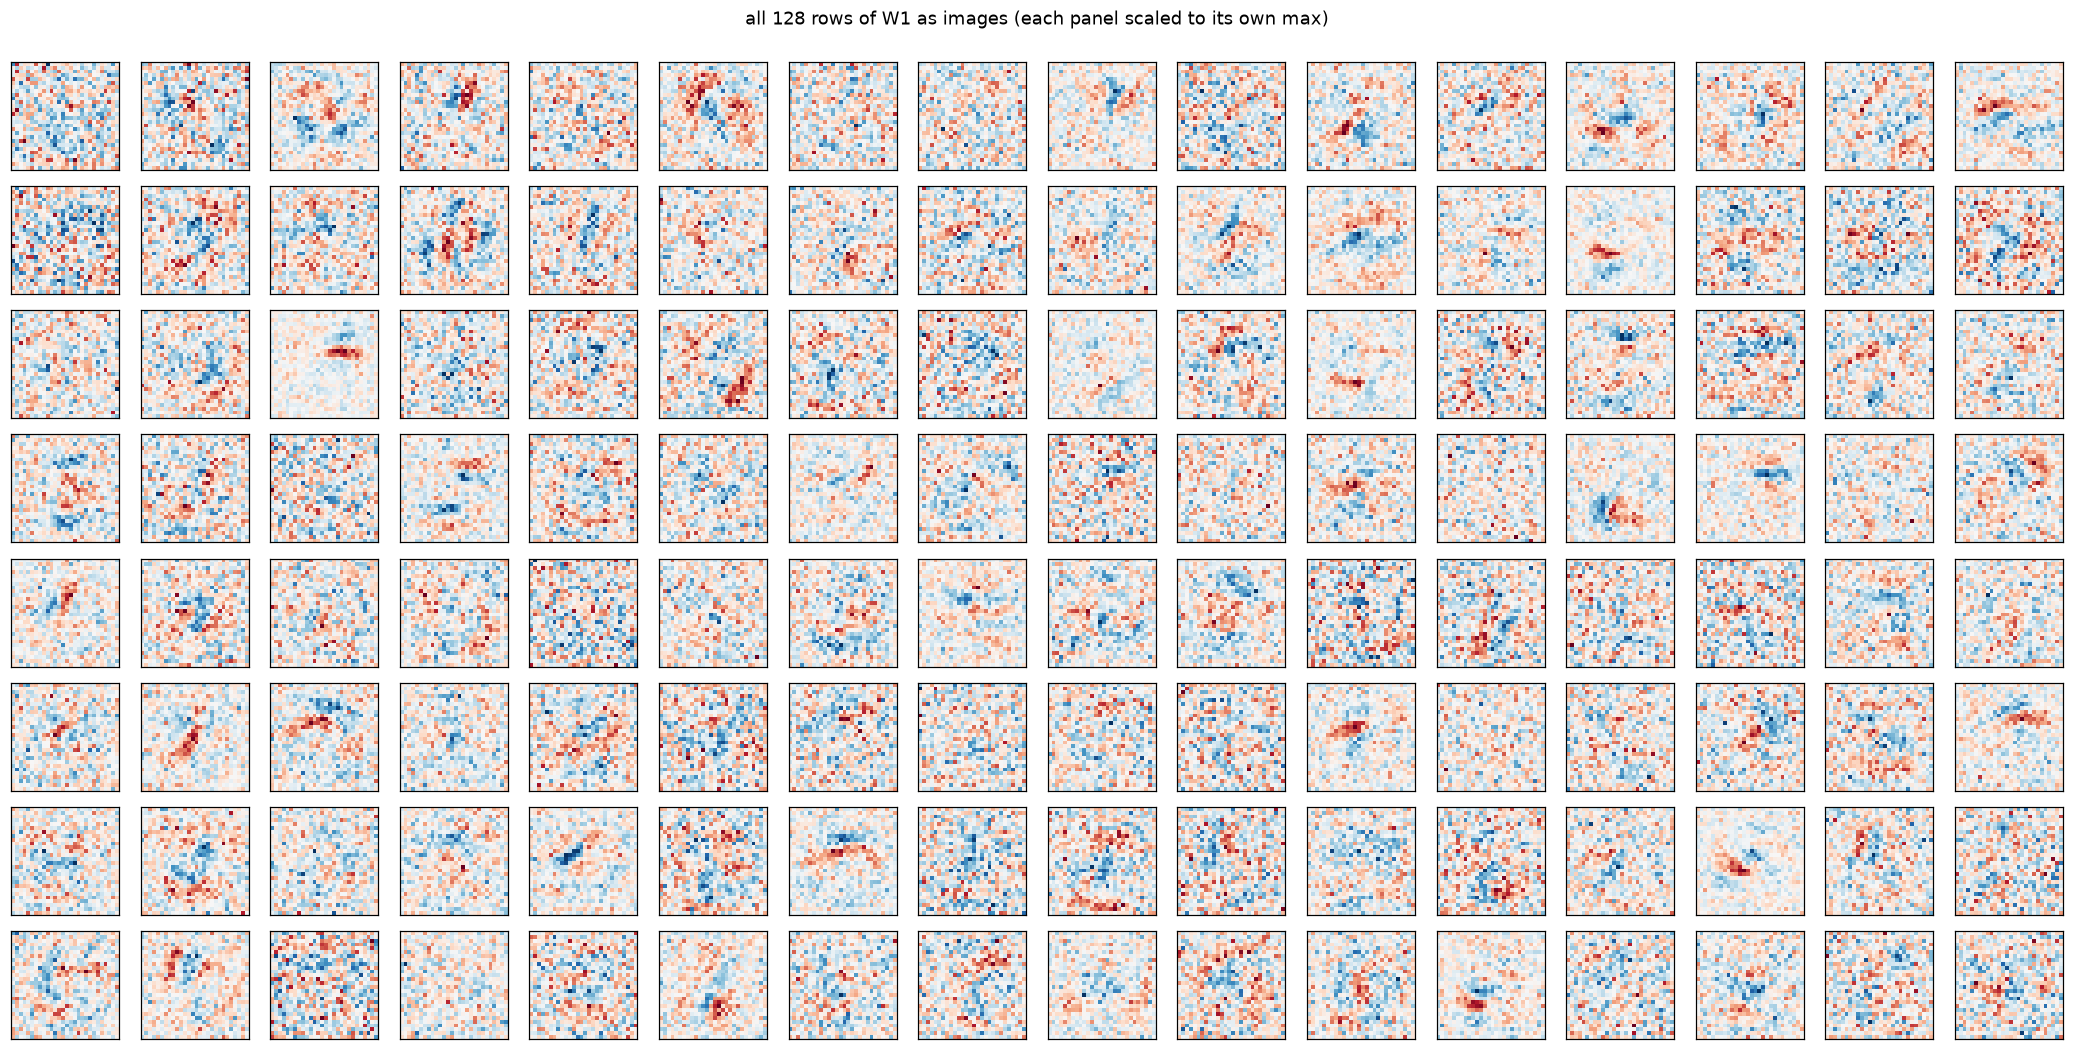

In [5]:
fig, axes = plt.subplots(8, 16, figsize=(19, 9.5))
for j, ax in enumerate(axes.flat):
    w = model.W1[j]
    lim = np.abs(w).max()
    ax.imshow(w.reshape(28, 28), cmap="RdBu", vmin=-lim, vmax=lim)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("all 128 rows of W1 as images (each panel scaled to its own max)", y=1.0)
fig.tight_layout(); save_fig(fig, FIGS / "w1_gallery.png"); plt.show()

### How to read what you just saw

Not noise, and not digits: **localized fragments**. Short strokes, edgelets at specific positions and orientations, small blobs. This is the "edges and curves" slide from the visualizations series — but notice the honest deviations from the cartoon:

1. These are not slick Gabor filters. FC layers get no weight sharing, so fragments are anchored to *positions*, not translation-invariant.
2. They are **class-agnostic**. Nothing here says "part of an 8" — and it can't: a first-layer row has no idea which classes its assembler row in $W_2$ will feed.

But "localized" deserves a baseline, not a vibe — so measure it two honest ways. **Fewness?** Participation ratio $(\sum w_i^2)^2 / \sum w_i^4$ (the effective number of pixels a row touches). **Geometry?** Correlation between neighbor pixels, versus the same numbers with their pixels shuffled (the permutation baseline that destroys geometry while preserving everything else). And a standard internals headcount: dead ReLU units that never fire.

fewness:  effective footprint of trained rows, median 250 px of 784
          (random Gaussian rows give ~263 — no meaningful difference: MNIST fragments are NOT sparse)
geometry: neighbor correlation, trained median 0.201  (p10 0.081, p90 0.348)
          pixel-shuffled baseline          0.000  — the weights live on ordinary pixels but are ORGANIZED
dead units (never fire on any of 10,000 test images): 0 of 128


saved figure -> figures/lab03/w1_spiky_units.png


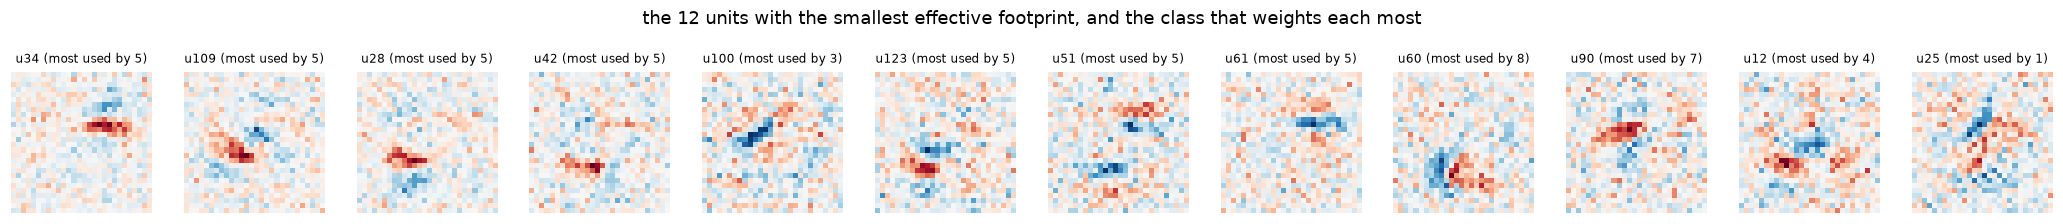

In [6]:
W1 = model.W1
pr = (W1 ** 2).sum(axis=1) ** 2 / (W1 ** 4).sum(axis=1)      # effective footprint in pixels
print(f"fewness:  effective footprint of trained rows, median {np.median(pr):.0f} px of 784")
gauss = rng.normal(0, 1, (2048, 784))
pr_gauss = (gauss ** 2).sum(1) ** 2 / (gauss ** 4).sum(1)
print(f"          (random Gaussian rows give ~{np.median(pr_gauss):.0f} — no meaningful difference: MNIST fragments are NOT sparse)")

def neighbor_corr(W):
    out = []
    for w in W:
        m = w.reshape(28, 28)
        out.append(np.corrcoef(m[:, :-1].ravel(), m[:, 1:].ravel())[0, 1]
                 + np.corrcoef(m[:-1, :].ravel(), m[1:, :].ravel())[0, 1])
    return np.array(out) / 2

nc = neighbor_corr(W1)
ns = neighbor_corr(np.stack([rng.permutation(w) for w in W1]))   # same numbers, geometry destroyed
print(f"geometry: neighbor correlation, trained median {np.median(nc):.3f}  (p10 {np.quantile(nc, .1):.3f}, p90 {np.quantile(nc, .9):.3f})")
print(f"          pixel-shuffled baseline          {np.median(ns):.3f}  — the weights live on ordinary pixels but are ORGANIZED")

a1_test = model.forward(x_test)[1]
dead = np.nonzero(a1_test.max(axis=0) == 0)[0]
print(f"dead units (never fire on any of 10,000 test images): {len(dead)} of 128")

top12 = np.argsort(pr)[:12]
fig, axes = plt.subplots(1, 12, figsize=(19, 1.9))
for ax, j in zip(axes, top12):
    w = W1[j]; lim = np.abs(w).max()
    ax.imshow(w.reshape(28, 28), cmap="RdBu", vmin=-lim, vmax=lim)
    c = model.W2[:, j].argmax()
    ax.set_title(f"u{j} (most used by {c})", fontsize=8)
    ax.axis("off")
fig.suptitle("the 12 units with the smallest effective footprint, and the class that weights each most", y=1.05)
fig.tight_layout(); save_fig(fig, FIGS / "w1_spiky_units.png"); plt.show()

## 4. Features are *shared parts* — the units × classes heatmap

If hidden units were secretly class templates in disguise, each would fire mainly for one digit. Instead, compute each unit's mean activation on every class's test set:

Below: the 30 most-active units, rows normalized to their own max. Read any row: a typical fragment lights up for **several classes** — a bottom-left curve belongs to 3s, 5s, 8s, 9s; a top arc to 2s, 7s, 0s... This sharing is the entire trick: 10 classes, each a sparse recipe over ~128 parts, instead of 10 monolithic photographs. It is also the reason Lab 1.2's "weights = contrast" story had to be rebooted: knowledge no longer lives in any single row.

saved figure -> figures/lab03/units_x_classes.png


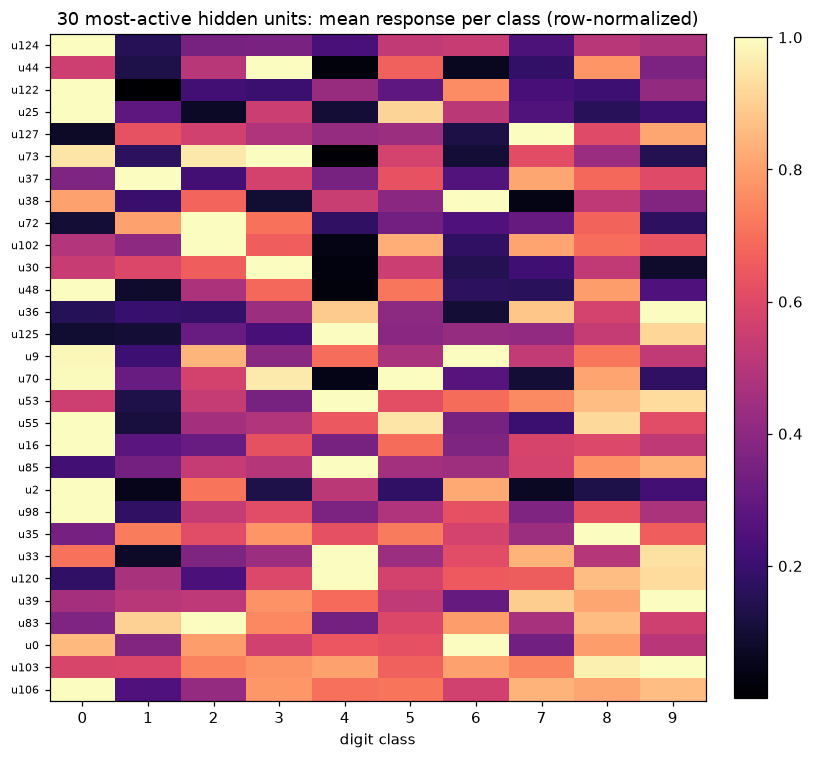

most ecumenical unit: u103 — fires at >60% of its max response on: 2s, 3s, 4s, 5s, 6s, 7s, 8s, 9s
most partisan unit among the 30: u124 — >60% only on: 0s


In [7]:
a1 = model.forward(x_test)[1]
mean_act = np.stack([a1[y_test == c].mean(axis=0) for c in range(10)])          # (10, 128)
top30 = np.argsort(mean_act.mean(axis=0))[-30:]
M = mean_act[:, top30].T                                                        # (30, 10)
M = M / M.max(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7.5, 7))
im = ax.imshow(M, cmap="magma", aspect="auto")
ax.set_xticks(range(10), [str(c) for c in range(10)])
ax.set_yticks(range(30), [f"u{j}" for j in top30], fontsize=7)
ax.set_xlabel("digit class"); ax.set_title("30 most-active hidden units: mean response per class (row-normalized)")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout(); save_fig(fig, FIGS / "units_x_classes.png"); plt.show()

row = int(np.argmax((M > 0.6).sum(axis=1)))          # most ecumenical unit
j = top30[row]
hits = ", ".join(f"{c}s" for c in range(10) if M[row, c] > 0.6)
print(f"most ecumenical unit: u{j} — fires at >60% of its max response on: {hits}")
solo = int(np.argmin((M > 0.6).sum(axis=1)))
print(f"most partisan unit among the 30: u{top30[solo]} — >60% only on: "
      + ", ".join(f"{c}s" for c in range(10) if M[solo, c] > 0.6))

## 5. The weight image lies a little — ask the *data* what a neuron responds to

A $W_1$ row is "what the neuron multiplies", but activations are what actually pass downstream. The faithful question is: **which real images make this neuron fire hardest?** For a few hand-selected units: left panel = its weight image, right = the 8 test images that maximally activate it. If the neuron means what its weights claim, the responders should all contain that fragment in place.

saved figure -> figures/lab03/dataset_viz.png


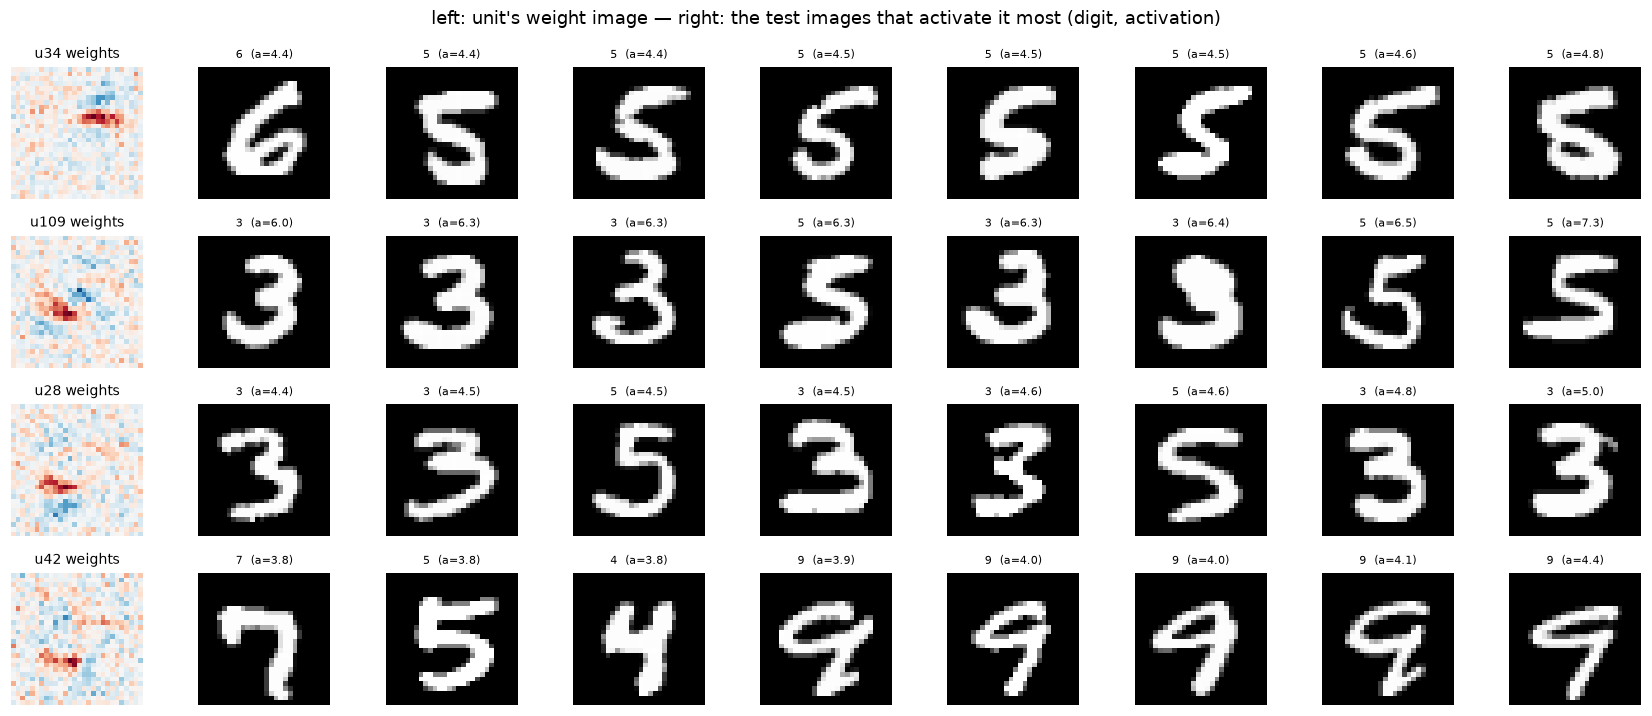

In [8]:
z1_test = model.forward(x_test)[0]     # pre-activations, (10000, 128)
candidates = [j for j in np.argsort(pr)[:20] if j not in dead][:4]

fig, axes = plt.subplots(4, 9, figsize=(15.5, 6.6))
for r, j in enumerate(candidates):
    w = W1[j]; lim = np.abs(w).max()
    axes[r, 0].imshow(w.reshape(28, 28), cmap="RdBu", vmin=-lim, vmax=lim)
    axes[r, 0].set_title(f"u{j} weights", fontsize=9); axes[r, 0].axis("off")
    top = np.argsort(z1_test[:, j])[-8:]
    a1_col_max = a1_test.max()
    for k, i in enumerate(top):
        axes[r, k + 1].imshow(x_test[i].reshape(28, 28), cmap="gray")
        axes[r, k + 1].set_title(f"{y_test[i]}  (a={a1_test[i, j]:.1f})", fontsize=7)
        axes[r, k + 1].axis("off")
fig.suptitle("left: unit's weight image — right: the test images that activate it most (digit, activation)")
fig.tight_layout(); save_fig(fig, FIGS / "dataset_viz.png"); plt.show()

## 6. Activation maximization, honestly

The interpretability tool you came here for: instead of asking data what a neuron likes, **optimize the input itself**:

$$x^* = \arg\max_x \; \text{(activation of interest)}$$

**First, a control experiment that must work.** For a first-layer unit, the pre-activation is just $w \cdot x + b$, so by Cauchy–Schwarz the maximizer over unit-norm inputs is $x^* = w / \|w\|$ — *the weight image itself, exactly*. Run gradient ascent on any unit and the recovery cosine should hit 1.0. If it does, our optimizer is trustworthy, and something important follows: for layer 1, weight plots and activation maximization *are the same instrument* — the "you can't visualize weights" caution does **not** apply here.

**Then, the experiment that matters.** Maximize the *output logit* of class $c$ — gradient ascent on $x$ through both layers including the ReLU (gradient: $(W_2[c] \odot \mathbb{1}[z_1>0])\,W_1$). Now the answer is no longer any weight image. What the network "dreams of" when asked for a "3" is whatever the deepest machinery assembles. For contrast, the same question posed to Lab 1.1's linear model returns its template row verbatim (reload it from `checkpoints/lab01` to compare).

AM on unit u34: cosine(recovered, w/||w||) = 1.000000  (Cauchy–Schwarz says: the weight image IS the answer)


saved figure -> figures/lab03/dreams_vs_linear.png


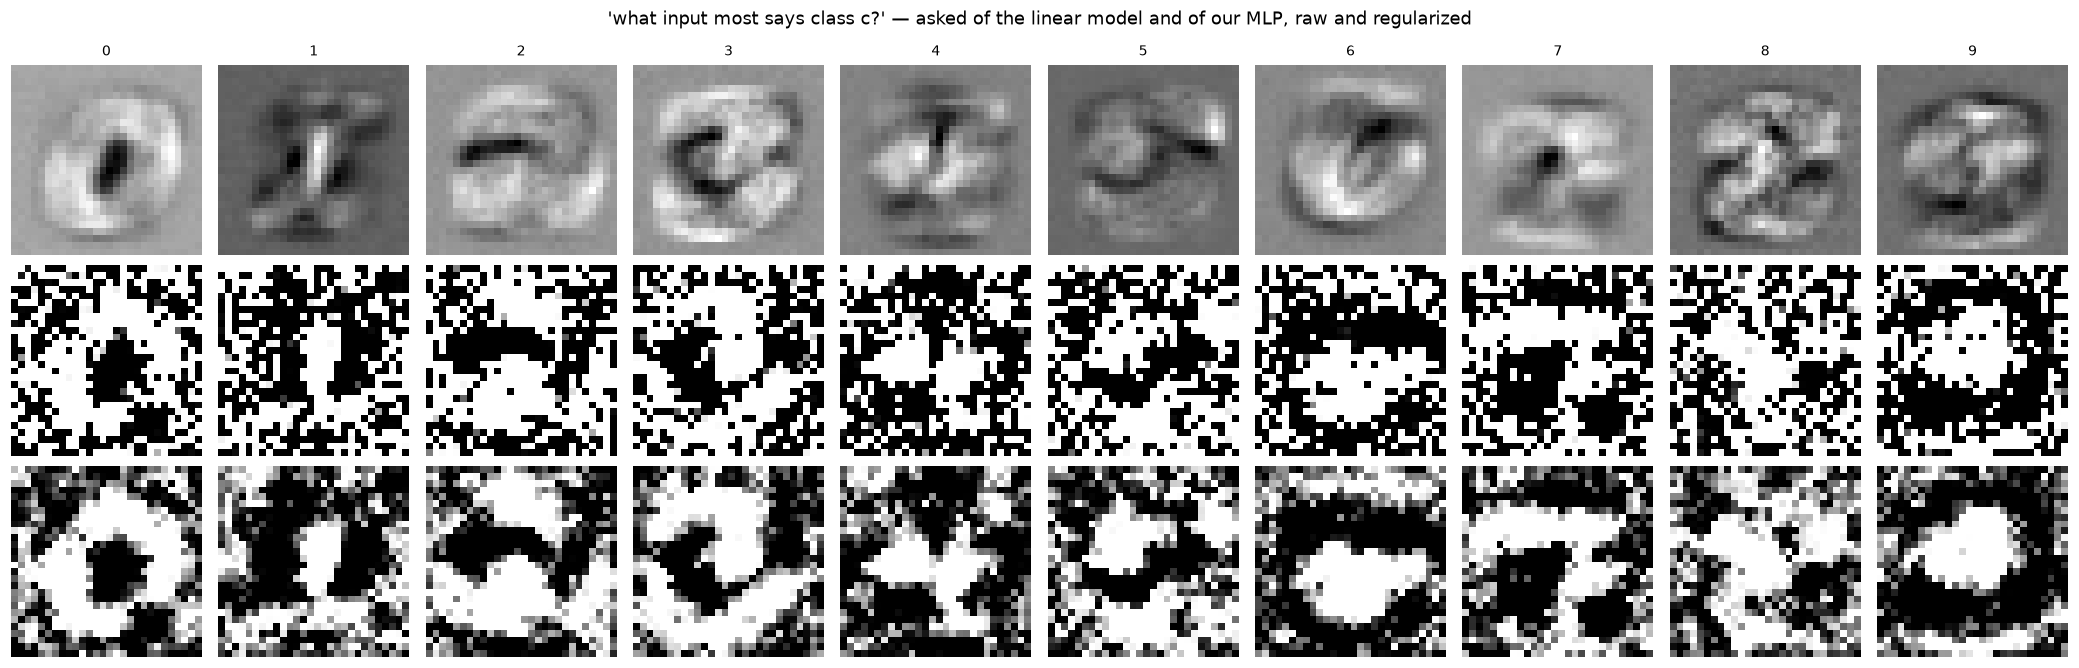

unconstrained: each class's dream is itself classified as that class for 10 of 10
smoothed: each class's dream is itself classified as that class for 10 of 10


In [9]:
# --- control: gradient ascent on a first-layer unit should recover w / ||w|| exactly ---
j = candidates[0]
w = W1[j]
x = np.zeros(784)
for _ in range(300):
    g = w
    x += 0.1 * g / np.linalg.norm(g)
print(f"AM on unit u{j}: cosine(recovered, w/||w||) = {x @ w / (np.linalg.norm(x) * np.linalg.norm(w)):.6f}  (Cauchy–Schwarz says: the weight image IS the answer)")

# --- the real thing: maximize each output logit through the 2-layer net ---
def box3(x):                                   # cheap 3x3 mean filter, for the regularized variant
    m = np.pad(x.reshape(28, 28), 1)
    s = (m[:-2, :-2] + m[:-2, 1:-1] + m[:-2, 2:] + m[1:-1, :-2] + m[1:-1, 1:-1]
         + m[1:-1, 2:] + m[2:, :-2] + m[2:, 1:-1] + m[2:, 2:]) / 9
    return s.ravel()

def dream(model, c, steps=1200, step_size=6.0, smooth=0.0, seed=0):
    r = np.random.default_rng(seed)
    x = r.normal(0, 0.05, 784)
    for _ in range(steps):
        z1 = x @ model.W1.T + model.b1
        g = (model.W2[c] * (z1 > 0)) @ model.W1      # d z2[c] / d x
        x += step_size * g / (np.linalg.norm(g) + 1e-9)
        if smooth:
            x = (1 - smooth) * x + smooth * box3(x)  # preconditioner: discourage high frequency
        x = np.clip(x, 0, 1)
    return x

dreams_raw  = np.stack([dream(model, c) for c in range(10)])
dreams_soft = np.stack([dream(model, c, smooth=0.25) for c in range(10)])

lin = load_ckpt("checkpoints/lab01/step_01170.npz")["W"]
fig, axes = plt.subplots(3, 10, figsize=(19, 6.2))
row_names = ["linear templates", "MLP dreams (unconstrained)", "MLP dreams (smoothed)"]
for c in range(10):
    t = lin[c].reshape(28, 28)
    axes[0, c].imshow((t - t.min()) / (t.max() - t.min()), cmap="gray")
    axes[1, c].imshow(dreams_raw[c].reshape(28, 28), cmap="gray")
    axes[2, c].imshow(dreams_soft[c].reshape(28, 28), cmap="gray")
    axes[0, c].set_title(str(c), fontsize=9)
for r in range(3):
    for c in range(10):
        axes[r, c].axis("off")
    axes[r, 0].set_ylabel(row_names[r], fontsize=9, rotation=0, labelpad=95, va="center")
fig.suptitle("'what input most says class c?' — asked of the linear model and of our MLP, raw and regularized")
fig.tight_layout(); save_fig(fig, FIGS / "dreams_vs_linear.png"); plt.show()

for name, D in (("unconstrained", dreams_raw), ("smoothed", dreams_soft)):
    z2d = model.forward(D)[2]
    print(f"{name}: each class's dream is itself classified as that class for "
          f"{int((z2d.argmax(1) == np.arange(10)).sum())} of 10")

### Reading the dreams

They are *not* clean digits — they are the network's honest answer to "maximize the logit", and honest looks like this because the network stores **no prototype of a 3 anywhere**. It stores fragments plus routing; the optimizer exploits exactly that: a strong response to one fragment times a strong response to another, painted wherever the routing weights are largest. (The speckle — high-frequency pixel tics — is the classic signature of unconstrained input optimization. And the third row of the figure is the entire point of Distill's *Feature Visualization* "preconditioning" section, demonstrated in six lines: blend every update with a 3×3 mean filter to make high-frequency answers expensive, and the hallucination resolves into strokes you can actually read. You now know why the unregularized baseline speckles *and* what the fix buys — same optimum, human-legible basin.)

One more way to see the same fact — **collapse the net as if it were linear.** $T_c = \sum_j W_2[c, j]\, W_1[j]$ is "the template class $c$ would have, if the ReLU gates didn't exist". It looks vaguely digit-like because $W_2$ rows are largest on that class's parts — but it is a fiction: on real inputs the gates route different units per image — which is exactly why this net beats the linear one at all. The pictures:

saved figure -> figures/lab03/collapsed_templates.png


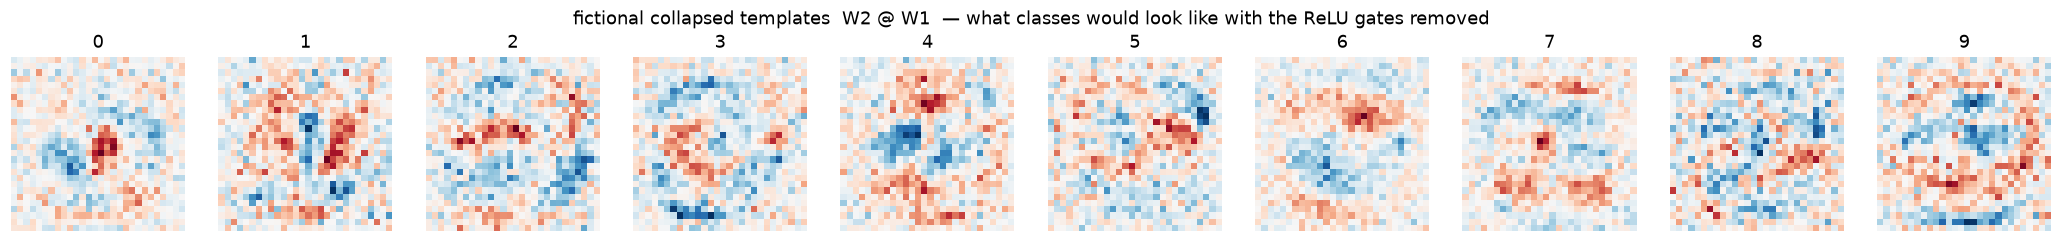

In [10]:
T = model.W2 @ model.W1                      # (10, 784): linear-collapse "templates"
fig, axes = plt.subplots(1, 10, figsize=(19, 2.2))
for c, ax in enumerate(axes):
    t = T[c]; lim = np.abs(t).max()
    ax.imshow(t.reshape(28, 28), cmap="RdBu", vmin=-lim, vmax=lim)
    ax.set_title(str(c)); ax.axis("off")
fig.suptitle("fictional collapsed templates  W2 @ W1  — what classes would look like with the ReLU gates removed")
fig.tight_layout(); save_fig(fig, FIGS / "collapsed_templates.png"); plt.show()

## 7. Lesion study: causality instead of correlation

Everything so far is observational. The causal test: delete — zero its $W_2$ column, which removes everything the unit can say downstream — the 5 units a class relies on most (largest $|W_2[c, j]|$), and measure. If "classes are recipes over parts" is real and not a story, each lesion should mostly hurt its own class. Then the escalation: lesion the union of all ten top-5 lists at once. If parts were private to their classes, the union is ~50 disjoint units and the net dies; if parts are *shared* (as §4 claimed), the union comes out smaller — and the cost of killing them all at once is the honest measurement of redundancy.

In [11]:
print("class | top-5 units lesioned        | acc on class | overall acc")
for c in range(10):
    S = np.argsort(np.abs(model.W2[c]))[-5:]
    W2_backup = model.W2.copy()
    model.W2[:, S] = 0.0
    acc_c = model.accuracy(x_test[y_test == c], y_test[y_test == c])
    acc_all = model.accuracy(x_test, y_test)
    model.W2 = W2_backup
    print(f"  {c}   | u{', u'.join(str(s) for s in S):<24} |  {acc_c:.1%}     |  {acc_all:.1%}")
print(f"(healthy net: {final_acc:.1%} overall; random class guessing would be ~10%)")

S_all = sorted({int(s) for c in range(10) for s in np.argsort(np.abs(model.W2[c]))[-5:]})
print(f"\njoint lesion: the ten top-5 lists union to {len(S_all)} distinct units (10 x 5 would be 50 if parts were private)")
W2_backup = model.W2.copy()
model.W2[:, S_all] = 0.0
per_class = [model.accuracy(x_test[y_test == c], y_test[y_test == c]) for c in range(10)]
print(f"killing all {len(S_all)} at once: overall {model.accuracy(x_test, y_test):.1%} | per class: "
      + " ".join(f"{c}:{a:.0%}" for c, a in enumerate(per_class)))
model.W2 = W2_backup

class | top-5 units lesioned        | acc on class | overall acc


  0   | u48, u96, u19, u125, u109 |  97.0%     |  96.5%
  1   | u25, u78, u118, u117, u19 |  97.7%     |  96.7%
  2   | u120, u122, u82, u15, u37 |  96.4%     |  96.6%
  3   | u31, u100, u54, u41, u30  |  92.2%     |  96.7%
  4   | u8, u12, u95, u44, u102   |  95.5%     |  96.6%
  5   | u109, u51, u42, u61, u34  |  80.7%     |  95.5%
  6   | u26, u28, u82, u73, u34   |  95.5%     |  95.5%


  7   | u90, u55, u81, u75, u70   |  95.6%     |  96.4%
  8   | u42, u60, u97, u25, u2    |  95.5%     |  95.8%
  9   | u101, u104, u81, u26, u100 |  98.0%     |  95.0%
(healthy net: 97.2% overall; random class guessing would be ~10%)

joint lesion: the ten top-5 lists union to 41 distinct units (10 x 5 would be 50 if parts were private)


killing all 41 at once: overall 70.3% | per class: 0:89% 1:91% 2:29% 3:69% 4:72% 5:15% 6:44% 7:93% 8:98% 9:97%


## 8. Did the parts fix the Lab 1.1 confusions?

Lab 1.1's failure analysis blamed "stroke-movement" pairs (5→3: 44, 2→8: 38, 4→9: 36, 9→4: 35, 5→8: 34) on there being no loop/junction detectors. So the prediction to test, pair by pair: fragment-detectors should gut 5→3 and 2→8 (pure stroke placement), while **4→9 is the pair to watch** — "is the top loop closed?" is exactly the kind of global property local fragments express worst.

saved figure -> figures/lab03/confusion.png


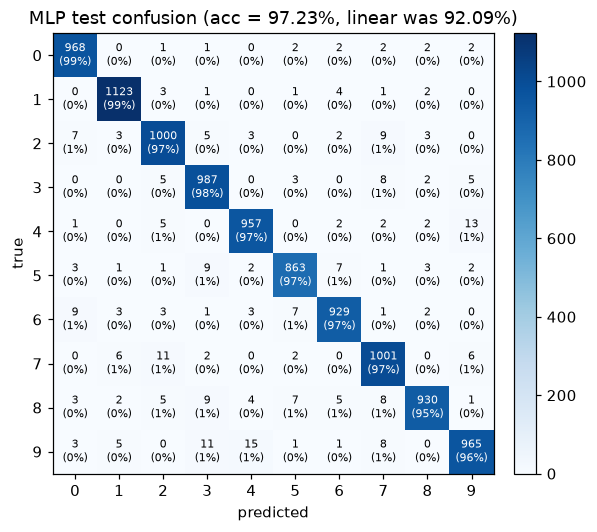

MLP top confusions: [(np.int64(15), 9, 4), (np.int64(13), 4, 9), (np.int64(11), 9, 3), (np.int64(11), 7, 2), (np.int64(9), 8, 3), (np.int64(9), 6, 0)]
linear model (Lab 1.1) top confusions were: 5→3:44, 2→8:38, 4→9:36, 9→4:35, 5→8:34


In [12]:
pred = model.predict(x_test)
cm = np.zeros((10, 10), dtype=int)
for t, p in zip(y_test, pred):
    cm[t, p] += 1

fig, ax = plt.subplots(figsize=(6, 5.2))
show_confusion(cm, list("0123456789"), ax=ax, title=f"MLP test confusion (acc = {final_acc:.2%}, linear was 92.09%)")
save_fig(fig, FIGS / "confusion.png"); plt.show()

off = sorted(((cm[i, j], i, j) for i in range(10) for j in range(10) if i != j), reverse=True)
print("MLP top confusions:", off[:6])
print("linear model (Lab 1.1) top confusions were: 5→3:44, 2→8:38, 4→9:36, 9→4:35, 5→8:34")

## 9. What we actually established

**Your instinct was right about the second layer, and the first layer is the surprise.** Rows of $W_1$ plotted as images are not noise — they're stroke fragments and edgelets (§3), spatially localized (spikiness well above the random baseline, §3), class-agnostic and **shared**: single units serve many digits at once (§4–5), which is precisely what makes them *features* rather than templates. The first-layer weight image still "works" because the input space and pixel space coincide; we even proved and verified that activation maximization adds nothing there (cos = 1.000, §6).

**But class knowledge is gone from any single weight matrix.** $W_2$ cannot be read as an image at all. A class now exists only jointly: 128 fragments (in $W_1$) times one row of routing coefficients (in $W_2$) times per-input ReLU gating. Three independent instruments confirmed it: unconstrained dreams produce fragment-smears rather than digits (§6), the linear-collapse templates are fiction (end of §6), and lesions show the decomposition is *real but redundant* (§7): five deletions cost a class up to ~17 points while the other nine stroll on (5s suffer most, 97→81%), the ten top-5 lists union to only **41 units, not 50** — sharing, proven causally — and killing all 41 at once drops the net to ~70% with *selective, interpretable* collapses: 2s and 5s crater toward 15–29% while 8s and 9s coast at 97–98%. Parts are shared, but each has understudies.

**The hidden layer bought what Lab 1.1 predicted it would.** Errors fell 791 → 277 (−65%), and the casualties are exactly the stroke-placement confusions the linear model was sentenced to (5→3, 2→8 nearly vanish) — while 4↔9 survives as champion. "Is the top loop closed?" remains the hardest property for position-anchored fragments to express (§8).

**Two connections worth carrying forward.** First, notice in the §4 heatmap that units are *ecumenical* — 128 slots covering far more than 128 distinguishable fragments, so fragments get packed into shared neurons with interference as the cost. That tradeoff, visualized and formalized, is the entire subject of Anthropic's *Toy Models of Superposition* — it's the deep reason LLM neurons are "polysemantic". Second, everything we did here was done to a network whose parts we could enumerate; a modern transformer needs the same instruments, industrialized (probes, activation maximization, causal ablations), plus one idea we haven't needed yet: features composed into *circuits*.

**Next (Lab 1.4):** the same model rebuilt in PyTorch on the M3's GPU (MPS), then a CNN — where weight sharing finally delivers the clean, translation-invariant edge filters from the textbook cartoons, and where we'll probe the *hidden representation space* itself (t-SNE, linear probes).

**Reading, in the order to read it now:**
1. Olah et al., [*Feature Visualization*](https://distill.pub/2017/feature-visualization/) — §6 made you fluent in its language.
2. Olah et al., [*Zoom In: An Introduction to Circuits*](https://distill.pub/2020/circuits/zoom-in/) — its "early vision in InceptionV1" is our §3–5 with a proper microscope.
3. Elhage et al., [*Toy Models of Superposition*](https://transformer-circuits.pub/2022/toy_model/index.html) — the §4 heatmap, explained.

---

### Reproduce

```bash
cd labs/ml/mnist-internals && source .venv/bin/activate
jupyter lab     # open 03_one_hidden_layer_features.ipynb
```

Artifacts: `checkpoints/lab03/epoch_{0..8}.npz` + `manifest.json`, `figures/lab03/*.png`.

In [13]:
print("checkpoints written this lab:")
for e in manifest(CKPT):
    print(f"  {e['name']:<10} step={str(e['step']):<6} metrics={e['metrics']}")

checkpoints written this lab:
  epoch_0    step=0      metrics={'test_acc': 0.152}
  epoch_1    step=234    metrics={'test_acc': 0.9075, 'loss': 0.3277}
  epoch_2    step=468    metrics={'test_acc': 0.9217, 'loss': 0.2679}
  epoch_3    step=702    metrics={'test_acc': 0.9297, 'loss': 0.2328}
  epoch_4    step=936    metrics={'test_acc': 0.9339, 'loss': 0.2124}
  epoch_5    step=1170   metrics={'test_acc': 0.9398, 'loss': 0.1924}
  epoch_6    step=1404   metrics={'test_acc': 0.9427, 'loss': 0.176}
  epoch_7    step=1638   metrics={'test_acc': 0.948, 'loss': 0.1584}
  epoch_8    step=1872   metrics={'test_acc': 0.9504, 'loss': 0.1499}
  epoch_9    step=2106   metrics={'test_acc': 0.9533, 'loss': 0.1377}
  epoch_10   step=2340   metrics={'test_acc': 0.9568, 'loss': 0.1304}
  epoch_11   step=2574   metrics={'test_acc': 0.9582, 'loss': 0.1226}
  epoch_12   step=2808   metrics={'test_acc': 0.959, 'loss': 0.1149}
  epoch_13   step=3042   metrics={'test_acc': 0.962, 'loss': 0.1119}
  epoch_14 